<a href="https://colab.research.google.com/github/SantiagoGuz13/Trabajo-/blob/main/Regresi%C3%B3n_Lineal_2222809.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODELOS  DE REGRESIÓN LINEAL EN PYTHON

In [ ]:
#Cargamos librerias
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from scipy.stats import spearmanr, kendalltau
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
#Cargar archivos en google
from google.colab import files
uploaded = files.upload()

Saving SB11_20231.TXT to SB11_20231.TXT


In [ ]:
datos_icfes = pd.read_csv(                      # Leer el archivo como un CSV
    io.BytesIO(uploaded['SB11_20231.TXT']), # Para cargar el archivo y subirlo directamente a google colab
    delimiter='¬',
    engine='python'                             # Se usa engine='python' para evitar la advertencia de Pandas,ya que el motor por defecto ('c') no soporta este tipo de separador
)
datos_icfes.head() #ver las primeras filas del DataFrame

,ESTU_TIPODOCUMENTO,ESTU_NACIONALIDAD,ESTU_GENERO,ESTU_FECHANACIMIENTO,PERIODO,ESTU_CONSECUTIVO,ESTU_ESTUDIANTE,ESTU_PAIS_RESIDE,ESTU_DEPTO_RESIDE,ESTU_COD_RESIDE_DEPTO,...,PUNT_INGLES,PERCENTIL_INGLES,DESEMP_INGLES,PUNT_GLOBAL,PERCENTIL_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,PERCENTIL_ESPECIAL_GLOBAL,ESTU_ESTADOINVESTIGACION
0,TI,COLOMBIA,F,04/11/2005,20231,SB11202310019049,ESTUDIANTE,COLOMBIA,CUNDINAMARCA,25,...,87.0,94.0,B+,422,100.0,67.532814,4.0,4,100.0,PUBLICAR
1,TI,COLOMBIA,M,08/04/2007,20231,SB11202310017318,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,326,NaN,47.223972,2.0,3,100.0,PUBLICAR
2,TI,COLOMBIA,F,26/05/2006,20231,SB11202310030916,ESTUDIANTE,COLOMBIA,VALLE,76,...,NaN,NaN,NaN,186,NaN,67.695519,4.0,3,40.0,PUBLICAR
3,CC,COLOMBIA,F,24/05/2004,20231,SB11202310074169,ESTUDIANTE,COLOMBIA,VALLE,76,...,58.0,43.0,A2,200,12.0,41.863163,2.0,3,58.0,PUBLICAR
4,TI,COLOMBIA,F,04/05/2005,20231,SB11202310044933,ESTUDIANTE,COLOMBIA,VALLE,76,...,69.0,57.0,B1,263,39.0,51.223795,3.0,3,92.0,PUBLICAR


In [ ]:
datos_icfes.info() #Ver el nombre de las columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12704 entries, 0 to 12703
Data columns (total 83 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ESTU_TIPODOCUMENTO             12704 non-null  object 
 1   ESTU_NACIONALIDAD              12704 non-null  object 
 2   ESTU_GENERO                    12704 non-null  object 
 3   ESTU_FECHANACIMIENTO           12704 non-null  object 
 4   PERIODO                        12704 non-null  int64  
 5   ESTU_CONSECUTIVO               12704 non-null  object 
 6   ESTU_ESTUDIANTE                12704 non-null  object 
 7   ESTU_PAIS_RESIDE               12704 non-null  object 
 8   ESTU_DEPTO_RESIDE              12704 non-null  object 
 9   ESTU_COD_RESIDE_DEPTO          12704 non-null  int64  
 10  ESTU_MCPIO_RESIDE              12704 non-null  object 
 11  ESTU_COD_RESIDE_MCPIO          12704 non-null  int64  
 12  ESTU_PRESENTACIONSABADO        12702 non-null 

In [ ]:
datos_icfes.describe() #Ver las estadísticas de las columnas numérica

,PERIODO,ESTU_COD_RESIDE_DEPTO,ESTU_COD_RESIDE_MCPIO,COLE_CODIGO_ICFES,COLE_COD_DANE_ESTABLECIMIENTO,SEED_CODIGOMEN,COLE_COD_DANE_SEDE,COLE_COD_MCPIO_UBICACION,COLE_COD_DEPTO_UBICACION,ESTU_COD_MCPIO_PRESENTACION,...,PERCENTIL_SOCIALES_CIUDADANAS,DESEMP_SOCIALES_CIUDADANAS,PUNT_INGLES,PERCENTIL_INGLES,PUNT_GLOBAL,PERCENTIL_GLOBAL,ESTU_INSE_INDIVIDUAL,ESTU_NSE_INDIVIDUAL,ESTU_NSE_ESTABLECIMIENTO,PERCENTIL_ESPECIAL_GLOBAL
count,12704.0,12704.000000,12704.000000,12704.000000,1.270400e+04,12704.000000,1.270400e+04,12704.000000,12704.000000,12704.000000,...,12704.00000,12704.000000,12702.000000,12702.000000,12704.000000,12702.000000,11855.000000,11855.000000,12704.000000,11.000000
mean,20231.0,46.861067,46930.803999,137812.243545,3.580633e+11,144.347607,3.580633e+11,47219.970954,47.107761,46800.813996,...,64.00063,2.851464,72.882066,65.866635,316.850362,65.505196,63.008162,3.422522,3.484572,88.000000
std,0.0,31.060190,31076.671884,212074.542023,4.236889e+10,62.767199,4.236889e+10,30787.343950,30.801400,31190.814381,...,24.36030,0.786343,13.992488,22.735517,48.062085,22.852094,7.426674,0.636775,0.531979,19.879638
min,20231.0,5.000000,5001.000000,182.000000,1.765200e+11,5.000000,1.765200e+11,5001.000000,5.000000,5001.000000,...,1.00000,1.000000,26.000000,1.000000,140.000000,1.000000,23.416927,1.000000,2.000000,40.000000
25%,20231.0,11.000000,11001.000000,19497.000000,3.118480e+11,68.000000,3.118480e+11,11001.000000,11.000000,11001.000000,...,47.00000,2.000000,63.000000,50.000000,286.750000,49.000000,58.184055,3.000000,3.000000,92.500000
50%,20231.0,68.000000,68276.000000,55657.000000,3.760010e+11,188.000000,3.760010e+11,68276.000000,68.000000,68001.000000,...,67.00000,3.000000,76.000000,68.000000,323.000000,68.000000,63.989899,3.000000,4.000000,97.000000
75%,20231.0,76.000000,76001.000000,124032.000000,3.760010e+11,188.000000,3.760010e+11,76001.000000,76.000000,76001.000000,...,84.00000,3.000000,82.000000,85.000000,352.000000,85.000000,68.540824,4.000000,4.000000,98.500000
max,20231.0,81.000000,81001.000000,809145.000000,4.768921e+11,272.000000,4.768921e+11,76892.000000,76.000000,81001.000000,...,100.00000,4.000000,100.000000,100.000000,478.000000,100.000000,83.007321,4.000000,4.000000,100.000000


In [ ]:
#Eliminación de valores faltantes en el análisis estadístico
icfes_sin_nan = datos_icfes[(~datos_icfes['ESTU_INSE_INDIVIDUAL'].isna()) &
 (~datos_icfes['PUNT_LECTURA_CRITICA'].isna()) &
 (~datos_icfes['PUNT_MATEMATICAS'].isna()) &
 (~datos_icfes['PUNT_C_NATURALES'].isna()) &
 (~datos_icfes['PUNT_SOCIALES_CIUDADANAS'].isna()) &
 (~datos_icfes['PUNT_INGLES'].isna())]

In [ ]:
#Modelo de Regresión con todas las variables numericas
tabla_regresion = datos_icfes[['ESTU_INSE_INDIVIDUAL','PUNT_LECTURA_CRITICA','PUNT_MATEMATICAS','PUNT_C_NATURALES','PUNT_SOCIALES_CIUDADANAS','PUNT_INGLES']]
tabla_regresion.head(4) #Ver las primeras filas

,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
0,67.532814,100,83,77,77,87.0
1,47.223972,67,58,68,68,NaN
2,67.695519,37,42,35,35,NaN
3,41.863163,45,41,41,27,58.0


<Axes: >

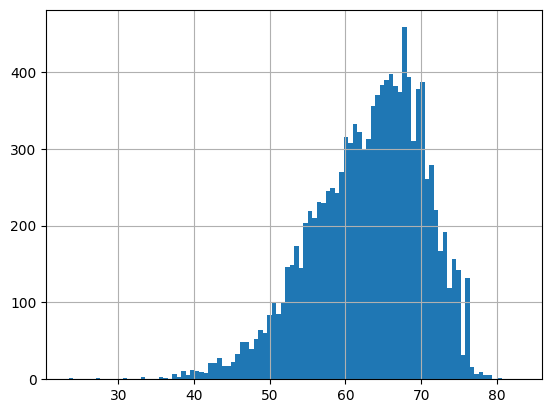

In [ ]:
tabla_regresion[("ESTU_INSE_INDIVIDUAL")].hist(bins=100) #Histograma de la variable dependiente

<Axes: >

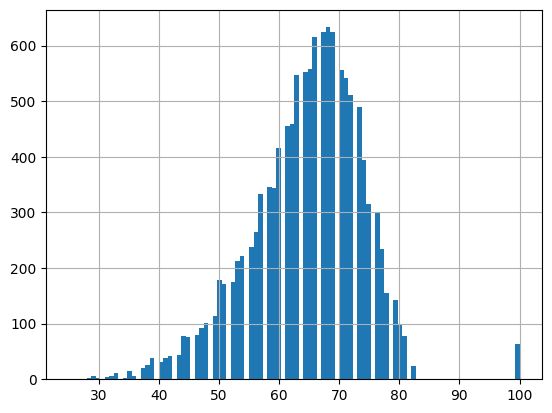

In [ ]:
tabla_regresion[("PUNT_LECTURA_CRITICA")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

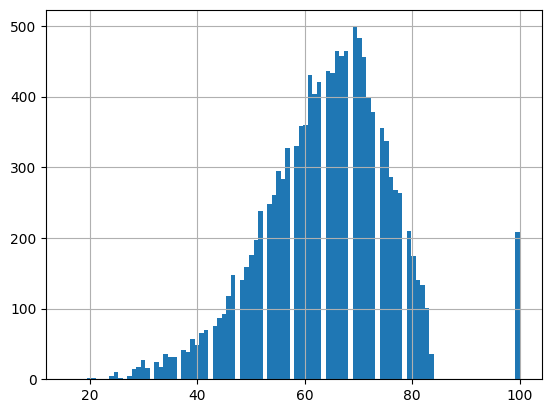

In [ ]:
tabla_regresion[("PUNT_MATEMATICAS")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

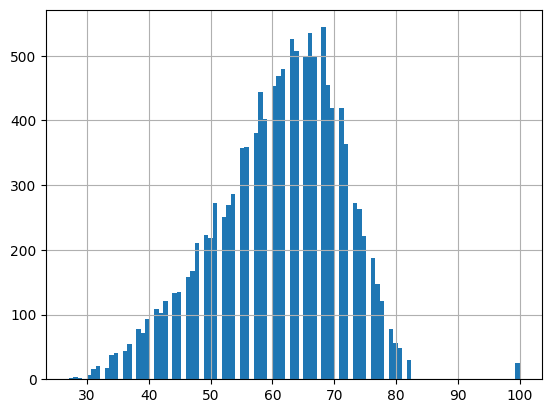

In [ ]:
tabla_regresion[("PUNT_C_NATURALES")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

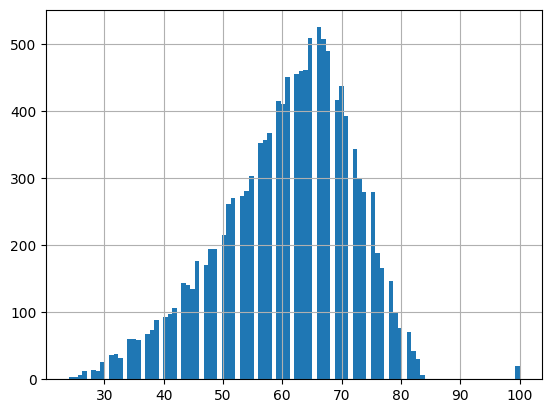

In [ ]:
tabla_regresion[("PUNT_SOCIALES_CIUDADANAS")].hist(bins=100) #Histograma de la variable explicativa

<Axes: >

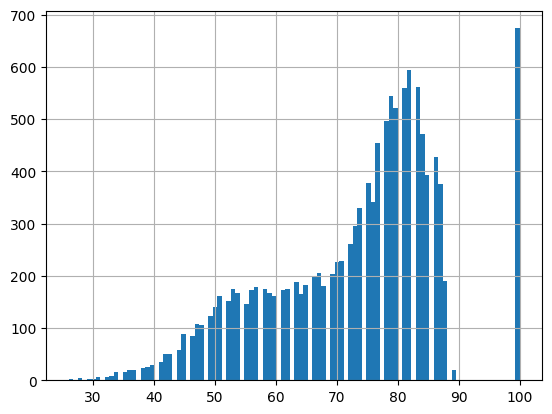

In [ ]:
tabla_regresion[("PUNT_INGLES")].hist(bins=100) #Histograma de la variable explicativa

Histograma de la variable dependiente con las variables explicativas

<Axes: >

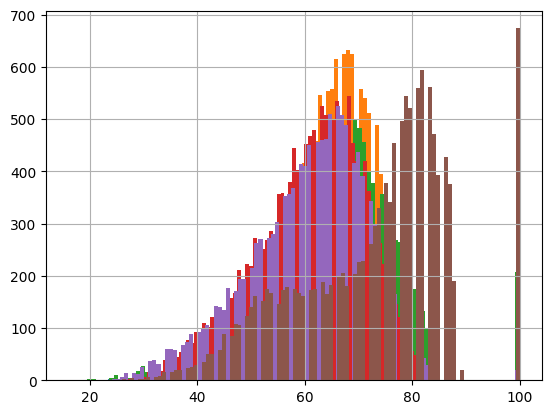

In [ ]:
tabla_regresion[("ESTU_INSE_INDIVIDUAL")].hist(bins=100) #Histograma de la variable dependiente en azul
tabla_regresion[("PUNT_LECTURA_CRITICA")].hist(bins=100) #Histograma de la variable explicativa en naranja
tabla_regresion[("PUNT_MATEMATICAS")].hist(bins=100) #Histograma de la variable explicativa en verde
tabla_regresion[("PUNT_C_NATURALES")].hist(bins=100) #Histograma de la variable explicativa en rojo
tabla_regresion[("PUNT_SOCIALES_CIUDADANAS")].hist(bins=100) #Histograma de la variable explicativa en morado
tabla_regresion[("PUNT_INGLES")].hist(bins=100) #Histograma de la variable explicativa en café

Se observa una barra en $100$ por lo cual vamos a limitar o eliminar datos no representativos para evitar distorciones en el análisis de los datos

In [ ]:
#Selección de datos no representativos para entrenar al modelo de regresión lineal
tabla_regresion1 = tabla_regresion[(tabla_regresion["ESTU_INSE_INDIVIDUAL"]<80) & (tabla_regresion["PUNT_LECTURA_CRITICA"]<90) &
                  (tabla_regresion["PUNT_MATEMATICAS"]<90) & (tabla_regresion["PUNT_C_NATURALES"]<90) & (tabla_regresion["PUNT_SOCIALES_CIUDADANAS"]<90) &
                  (tabla_regresion["PUNT_INGLES"]<90)]

#Visualización de los primeros cinco elementos
tabla_regresion1.head(5)

,ESTU_INSE_INDIVIDUAL,PUNT_LECTURA_CRITICA,PUNT_MATEMATICAS,PUNT_C_NATURALES,PUNT_SOCIALES_CIUDADANAS,PUNT_INGLES
3,41.863163,45,41,41,27,58.0
4,51.223795,53,55,41,56,69.0
5,57.690401,63,38,60,59,45.0
6,39.984838,69,60,59,51,50.0
7,50.613232,57,68,74,61,52.0


# Diagrama de Dispersión

In [ ]:
x = np.array(tabla_regresion1['ESTU_INSE_INDIVIDUAL']).reshape(-1, 1)  #Tipo numpy para una columna
y = tabla_regresion1['PUNT_INGLES']
trainx, testx, trainy, testy = train_test_split(x,y, test_size= 0.2, random_state= 0) #Tomar variables de entrenamiento
modelo_lineal0 = LinearRegression() #Carga de función lineal
regresion0 = modelo_lineal0.fit(trainx,trainy) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal0 = regresion0.predict(testx)  #Predicción datos de validación

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_LECTURA_CRITICA


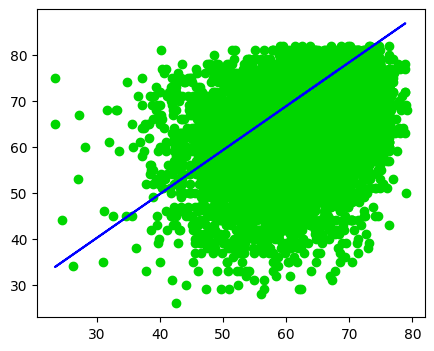

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_LECTURA_CRITICA"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de lectura critica en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_MATEMATICAS


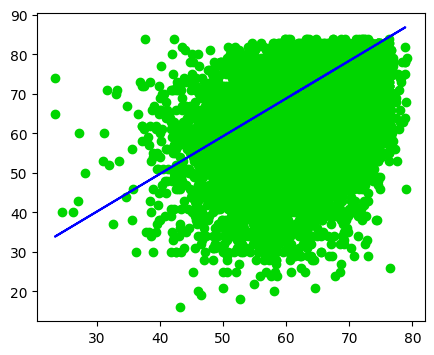

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_MATEMATICAS"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_

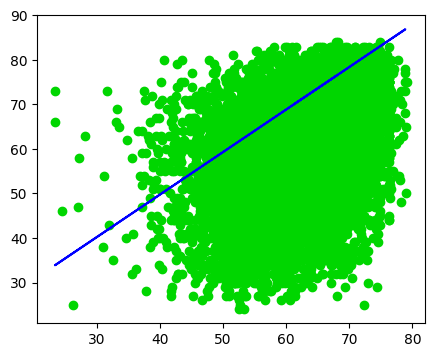

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_SOCIALES_CIUDADANAS"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

- Diagrama de Dispersión para ESTU_INSE_INDIVIDUAL y PUNT_INGLES


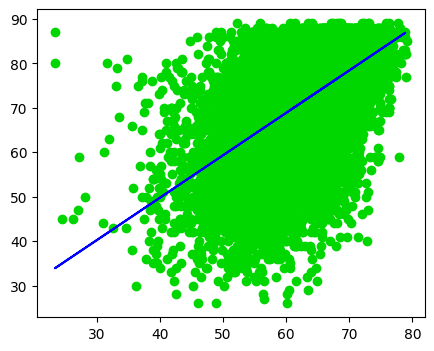

In [ ]:
#Elaboración de diagramas de dispersión, reconocer variables explicativas y no explicativas

plt.figure(figsize=(5,4)) #Genera el tamaño de la figura
plt.scatter(tabla_regresion1["ESTU_INSE_INDIVIDUAL"],tabla_regresion1["PUNT_INGLES"], c="#00D600") #Diagrama de dispersión, con
                                                                                                            #tabla_regresion1["PUNT_LECTURA_CRITICA"] → valores del eje X (variable explicativa)
                                                                                                            #tabla_regresion1["ESTU_INSE_INDIVIDUAL"] → valores del eje Y (variable respuesta)

plt.plot(testx, pred_lineal0, linestyle = "-", color= "blue")
plt.show()

Mediante el diagrama de dispersión podemos observar que amedida de que el puntaje de matemáticas en la  prueba ICFES aumenta el índice socioeconómico individual muestra un comportamiento también a crecer, generando una posible dependendependencia débil de las variables de estudio ya que el índice socioeconómico no explica de manera significativa el desempeño en la prueba.

# Coeficientes de Correlación

In [ ]:
#Puntaje Matemáticas vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_MATEMATICAS'], tabla_regresion1['PUNT_C_NATURALES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Matemáticas vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Matemáticas vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.794614
           Spearman 0.801006
            Kendall 0.620175


In [ ]:
#Puntaje Inglés vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_INGLES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Inglés vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Inglés vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.621238
           Spearman 0.601058
            Kendall 0.436750


In [ ]:
#Puntaje Ciencias Naturales vs Lectura Crítica
pearson = np.corrcoef(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_C_NATURALES'], tabla_regresion1['PUNT_LECTURA_CRITICA'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Ciencias Naturales vs Lectura Crítica")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Ciencias Naturales vs Lectura Crítica
Tipo de Coeficiente    Valor
            Pearson 0.733915
           Spearman 0.727555
            Kendall 0.549636


In [ ]:
#Puntaje Sociales y Ciudadanas vs Ciencias Naturales
pearson = np.corrcoef(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])[0,1]
spearman, _ = spearmanr(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])
kendall, _ = kendalltau(tabla_regresion1['PUNT_SOCIALES_CIUDADANAS'], tabla_regresion1['PUNT_C_NATURALES'])
df_resultados = pd.DataFrame({
    'Tipo de Coeficiente': ['Pearson', 'Spearman', 'Kendall'],
    'Valor': [pearson, spearman, kendall]
})
print("\n Coeficientes de Correlación Sociales y Ciudadanas vs Ciencias Naturales")
print(df_resultados.to_string(index=False))


 Coeficientes de Correlación Sociales y Ciudadanas vs Ciencias Naturales
Tipo de Coeficiente    Valor
            Pearson 0.781858
           Spearman 0.776094
            Kendall 0.594792


- Como los coeficientes de Pearson y Spearman en cada unos de los pares analizados son muy similares o cercanos nos indica que la relación entre los puntajes no solo es fuerte y positiva, sino que se ajusta muy bien a un modelo lineal además demuestra que no hay una distorsión extrema o sesgos drásticos en la tendencia central.
- Para kendall tenemos que siempre es menor tanto al de Spearman como al de Pearson lo cual es normal ya que es más riguroso


Recta de Regresión

In [ ]:
modelo_lineal = LinearRegression() #Carga de función lineal
regresion = modelo_lineal.fit(trainX,trainY) #Reconocimiento de variable respuesta y explicativas (Datos de entrenamiento)
pred_lineal = regresion.predict(testX)  #Predicción datos de validación

NameError: name 'trainX' is not defined

##MODELO DE REGERESIÓN LINEAL MULTIPLE
- **Datos de entrenamiento:** Datos con los cuales se entrena el modelo son aquellos con los que se estiman los parámetros

```
Diagrama de dispersión, con variable respuesta
'ESTU_INSE_INDIVIDUAL' y con todas las variables explicativas
'PUNT_LECTURA_CRITICA', 'PUNT_MATEMATICAS', 'PUNT_C_NATURALES',
'PUNT_SOCIALES_CIUDADANAS' y 'PUNT_INGLES'

```
ESTU_INSE_INDIVIDUAL = a1 PUNT_LECTURA_CRITICA + a2 PUNT_MATEMATICAS + a3 PUNT_C_NATURALES + a4 PUNT_SOCIALES_CIUDADANAS + a5 PUNT_INGLES + b + E

E ~ Normal (0, sigma^2)

Generalmente se toman 80% de los datos para de entrenamiento y 20% de validación.

Calculo de las esperanzas

- **Datos de validación:** Son los datos con los cuales se determina si el modelo implementado tiene un buen ajuste o no.

In [ ]:
X = tabla_regresion1.drop("ESTU_INSE_INDIVIDUAL", axis = 1) #Eliminación de la columna correspondiente a la variable respuesta
Y = tabla_regresion1["ESTU_INSE_INDIVIDUAL"] #Define la variable respuesta.
trainX, testX, trainY, testY = train_test_split(X, Y, test_size= 0.2, random_state= 0)  #Identifica datos de entrenamiento y validación
                                                                                        #Tamaño de los datos de validación corresponde a 20%
trainX.head(4) #Visualizar los primeros datos de entrenamiento